# Big Time Adolescence: Sundance darling meets lockdown
An analytics project on critic and audience reception and release context, plus cast film-output trends.

**Data honesty note:** every number in `data_*.csv` was taken from a web source listed in the `source` column. Box office is effectively unavailable (the film's March 2020 release collided with COVID closures), so this notebook leans on reception data and release timing. Sample sizes are small; treat results as descriptive, not statistical proof.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
OUT = Path('charts'); OUT.mkdir(exist_ok=True)
rec = pd.read_csv('data_reception.csv'); tl = pd.read_csv('data_timeline.csv', parse_dates=['date']); ctx = pd.read_csv('data_context.csv')
rec

,film,source,group,positive,mixed,negative,n,score,scale,note
0,Big Time Adolescence,Metacritic,critics,15,6,0,21,64.0,100,Metascore (21 reviews)
1,Big Time Adolescence,Metacritic,users,22,6,3,31,7.1,10,User score (31 ratings)
2,Never Rarely Sometimes Always,Metacritic,critics,37,1,0,38,91.0,100,Metascore (snapshot; distribution from critic-...


## 1. Reception: do critics and audiences agree?

In [2]:
for c in ['positive','mixed','negative']:
    rec[c+'_pct'] = (rec[c]/(rec.positive+rec.mixed+rec.negative)*100).round(1)
rec['label'] = rec.film.str.replace('Never Rarely Sometimes Always','NRSA') + ' (' + rec.group + ')'
rec[['label','n','positive_pct','mixed_pct','negative_pct']]

,label,n,positive_pct,mixed_pct,negative_pct
0,Big Time Adolescence (critics),21,71.4,28.6,0.0
1,Big Time Adolescence (users),31,71.0,19.4,9.7
2,NRSA (critics),38,97.4,2.6,0.0


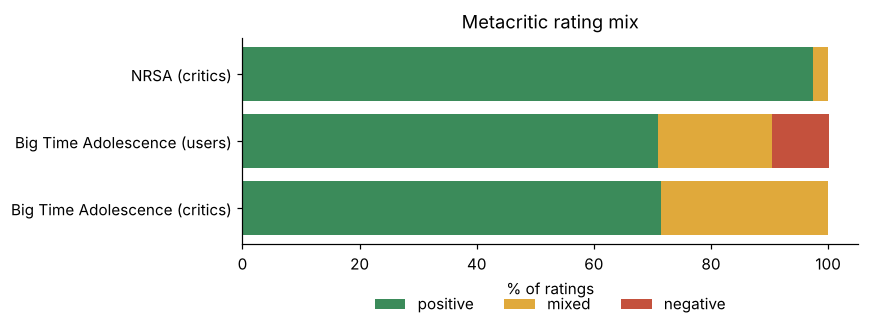

In [3]:
fig, ax = plt.subplots(figsize=(8,3.4))
cols = {'positive_pct':'#3b8b5a','mixed_pct':'#e0a93b','negative_pct':'#c4513d'}
left = [0]*len(rec)
for c,color in cols.items():
    ax.barh(rec.label, rec[c], left=left, color=color, label=c.split('_')[0])
    left = [l+v for l,v in zip(left, rec[c])]
ax.set_xlabel('% of ratings'); ax.set_title('Metacritic rating mix'); ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5,-0.4))
plt.tight_layout(); plt.savefig(OUT/'reception_mix.png', bbox_inches='tight'); plt.show()

In [4]:
bta = rec[rec.film=='Big Time Adolescence'].set_index('group')
critic10 = bta.loc['critics','score']/10; user10 = bta.loc['users','score']
print(f'Critics {critic10:.1f}/10 vs users {user10:.1f}/10 -> users rate it {user10-critic10:+.1f} higher')
print(f"Positive share: critics {bta.loc['critics','positive_pct']}% vs users {bta.loc['users','positive_pct']}%")
print(f"Negative share: critics {bta.loc['critics','negative_pct']}% vs users {bta.loc['users','negative_pct']}%")

Critics 6.4/10 vs users 7.1/10 -> users rate it +0.7 higher
Positive share: critics 71.4% vs users 71.0%
Negative share: critics 0.0% vs users 9.7%


**Reading it:** Critics and users are almost identical on the share of positive ratings (about 71% each), but users are a bit warmer on average and also more polarized: no critic was negative, while about 10% of users were. Versus the peer film in this release week, *Never Rarely Sometimes Always*, BTA is a solid-but-not-acclaimed comedy rather than an awards-circuit drama.

## 2. Release context: a 410-day wait, then lockdown

        date                              event  days_since_premiere
0 2019-01-28            Sundance world premiere                    0
1 2020-03-13  Limited theatrical release (Neon)                  410
2 2020-03-20             Hulu streaming release                  417


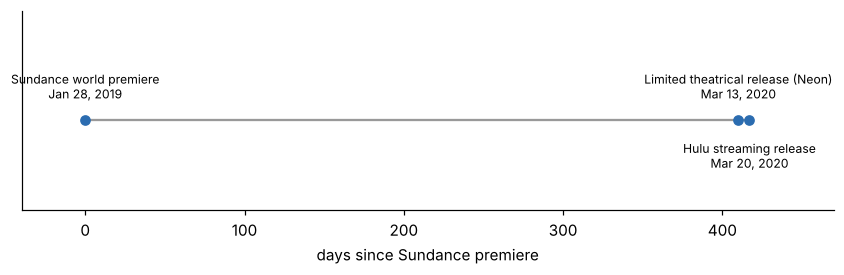

In [5]:
tl = tl.sort_values('date'); tl['days_since_premiere'] = (tl.date - tl.date.min()).dt.days
print(tl[['date','event','days_since_premiere']])
fig, ax = plt.subplots(figsize=(8,2.6))
ax.hlines(0, 0, tl.days_since_premiere.max(), color='#999')
for i, (_, r) in enumerate(tl.iterrows()):
    below = (i == 2); ax.plot(r.days_since_premiere, 0, 'o', color='#2b6cb0')
    ax.annotate(f"{r.event}\n{r.date:%b %d, %Y}", (r.days_since_premiere,0), xytext=(0,-14 if below else 12), textcoords='offset points', ha='center', va='top' if below else 'bottom', fontsize=8)
ax.set_ylim(-1,1.2); ax.set_xlim(-40, 470); ax.set_yticks([]); ax.set_xlabel('days since Sundance premiere'); plt.tight_layout(); plt.savefig(OUT/'timeline.png', bbox_inches='tight'); plt.show()

In [6]:
ctx

,item,value,source
0,Hulu acquisition price (USD),4000000.0,Deadline via Alt Press (reported)
1,Rotten Tomatoes at Sundance/pickup,90.0,Alt Press (early snapshot; not a current figure)
2,Domestic box office,NaN,The Numbers and Box Office Mojo list no figure
3,Rotten Tomatoes Tomatometer (current listing),86.0,Rotten Tomatoes (Griffin Gluck filmography page)
4,Rotten Tomatoes audience score (current listing),80.0,Rotten Tomatoes (Griffin Gluck filmography page)


Only **7 days** separate the limited theatrical release from Hulu. The film was a streaming title in practice from the start, which is why theatrical box office is blank and why attention proxies (Trends, pageviews) are the right next data to add.

## 3. Cast trajectories
Do the film's cast members' careers look different after 2019? Proxy: **credited scripted feature-film roles per year** (live action or voice), compared across 2016 to 2018 and 2020 to 2025. Year is the first public premiere year. Excludes TV, documentaries, concerts and appearances as oneself. The counts are a **lower bound** built from the cited web sources, not an exhaustive filmography.

In [7]:
cast = pd.read_csv('data_cast.csv')
order = ['Pete Davidson','Griffin Gluck','Sydney Sweeney','Machine Gun Kelly']
pre = cast[cast.year.between(2016,2018)].groupby('person').size().reindex(order, fill_value=0)/3
post = cast[cast.year.between(2020,2025)].groupby('person').size().reindex(order, fill_value=0)/6
tab = pd.DataFrame({'films_per_yr_2016_18':pre.round(2),'films_per_yr_2020_25':post.round(2)}); tab['change'] = (tab.iloc[:,1]-tab.iloc[:,0]).round(2); tab

,films_per_yr_2016_18,films_per_yr_2020_25,change
person,,,
Pete Davidson,0.33,2.33,2.00
Griffin Gluck,1.00,0.83,-0.17
Sydney Sweeney,0.67,2.00,1.33
Machine Gun Kelly,1.67,1.00,-0.67


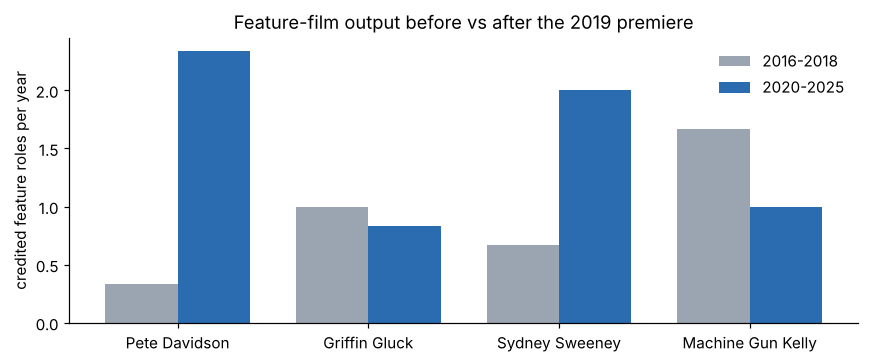

In [8]:
fig, ax = plt.subplots(figsize=(8,3.4)); x = range(len(order)); w = 0.38
ax.bar([i-w/2 for i in x], pre, w, label='2016-2018', color='#9aa5b1'); ax.bar([i+w/2 for i in x], post, w, label='2020-2025', color='#2b6cb0')
ax.set_xticks(list(x)); ax.set_xticklabels(order); ax.set_ylabel('credited feature roles per year'); ax.set_title('Feature-film output before vs after the 2019 premiere'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/'cast_output.png', bbox_inches='tight'); plt.show()

In [9]:
yr = cast.pivot_table(index='year', columns='person', values='title', aggfunc='count', fill_value=0)[order]
yr.loc[2013:2026].T

year,2013,2014,2015,2016,2018,2019,2020,2021,2022,2023,2024,2025,2026
person,,,,,,,,,,,,,
Pete Davidson,0,1,1,0,1,2,1,1,3,5,1,3,0
Griffin Gluck,0,0,2,2,1,2,1,1,1,0,2,0,1
Sydney Sweeney,1,0,0,1,1,1,1,2,0,3,3,3,0
Machine Gun Kelly,0,0,0,4,1,3,2,1,3,0,0,0,0


**Reading it:** The cast did not move together. Pete Davidson (about 0.3 to 2.3 roles a year) and Sydney Sweeney (about 0.7 to 2.0) show a clear rise in film credits after 2019. Griffin Gluck (1.0 to 0.8) and Machine Gun Kelly (1.7 to 1.0) are flat or lower in film credits. This is only film credits: it ignores TV (for example Sweeney's TV work) and music, and it cannot say the film caused any change.

## Limitations
- Small rating samples (21 critic reviews, 31 user ratings) from a single aggregator.
- RT ~90% is an early snapshot reported at the time of the Hulu pickup.
- No box office, no viewership: Hulu does not publish it.
- Peer comparison covers only one film (Never Rarely Sometimes Always).
- Cast counts are a lower bound from web sources, film credits only, and show association, not causation. Some release years differ between sources (Riff Raff, Americana, Eden); premiere year is used.